# 06 · Agrupamiento: perfiles de muestra y segmentos de clientes

Aquí no hay una respuesta correcta que predecir: se busca si las muestras (y, en un segundo
análisis, los clientes) se reparten en grupos con un perfil reconocible y útil para la operación.
Se usan los dos métodos del curso, K-means y DBSCAN, sobre tablas construidas solo con fechas de
desarrollo.

← Anterior: [05 · Clasificación y Bayes](05_clasificacion_bayes.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [07 · Evaluación final](07_evaluacion_final.ipynb) →

## Código del proyecto

La celda siguiente recrea el paquete `proyecto/` dentro de la sesión, de forma que el notebook funciona en Google Colab sin clonar ningún repositorio: basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo. La sección puede plegarse desde su título. Trae también los guiones de las etapas anteriores: si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (49 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 5 etapas previas (se reconstruyen si faltan);
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (65 archivos, 183 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="56b683a62dc78f56354f99870bd8c88e36ba4028914b1fe5e0b570320626573f",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import agrupamiento

iniciar_etapa("06_agrupamiento")
c = agrupamiento.iniciar()
mostrar(c.encabezado)

## 1. Qué se agrupa y con qué reglas

El cribado eligió un análisis con su regla fija; además se conserva uno complementario, fuera de la
regla, porque al laboratorio le interesan sus clientes. Las reglas de decisión se fijan antes de ver
resultados, para que ningún número de grupos se acomode a lo que se quiere ver. Los datos son
simulados: los grupos describen el mecanismo de la simulación y sus lecturas son un ejercicio de
método.

In [2]:
agrupamiento.reglas(c).mostrar()

## 2. Análisis seleccionado: perfiles de muestra

### 2.1 Preparación: por qué escalar

K-means y DBSCAN deciden con distancias euclidianas, que suman diferencias en unidades distintas
(mililitros, horas, días, UFC): sin escalar, la variable de mayor varianza decide casi sola quién
está cerca de quién. El estadístico de Hopkins compara la distancia entre vecinos reales con la de
puntos al azar (por encima de 0.5 hay tendencia a agruparse, sin decir cuántos grupos).

In [3]:
agrupamiento.preparacion(c, "seleccionado").mostrar()

### 2.2 K-means: número de grupos

La inercia siempre baja al aumentar k, así que el codo solo orienta; la elección se apoya en la
silueta, que sí penaliza partir un grupo que no debía partirse.

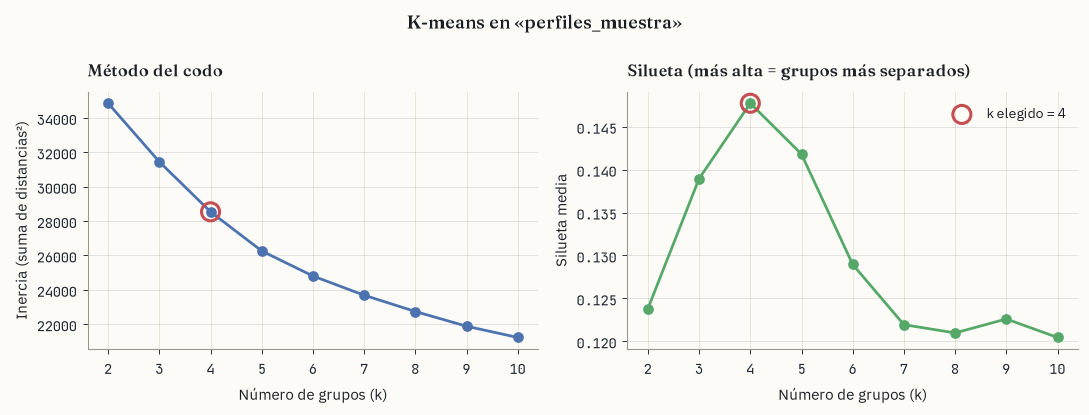

In [4]:
agrupamiento.kmeans(c, "seleccionado").mostrar()

### 2.3 DBSCAN: grupos por densidad

DBSCAN recibe un radio (eps) y un mínimo de vecinos (min_samples) y deja como ruido los puntos sin
suficientes vecinos cerca. La curva de k-distancias orienta la franja de eps. Los puntos de ruido no
son errores: son los casos que vale la pena revisar a mano.

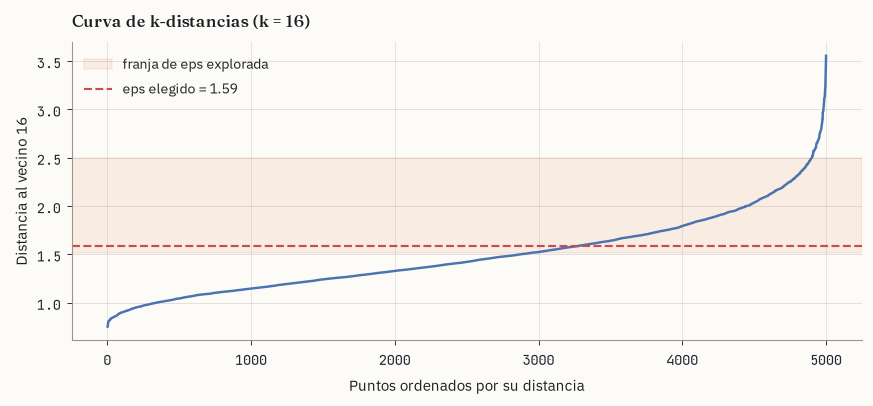

eps,min_samples,Grupos,Ruido,Silueta (sin ruido)
1.36,8,4,0.199,0.103
1.42,8,3,0.156,0.149
1.48,8,3,0.120,0.280
1.55,8,2,0.089,0.313
1.64,8,2,0.060,0.309
1.75,8,2,0.037,0.307
1.93,8,1,0.018,—
2.31,8,1,0.003,—
1.52,16,2,0.170,0.319
1.59,16,2,0.127,0.314


id_muestra,id_cliente,matriz,ensayo,volumen de muestra,hora de recepción,temperatura de transporte,horas de transporte,días prometidos,carga del día,control ambiental,días de entrega,Variable más apartada
M005080,C078,superficie,mesófilos aerobios,1079.00,12.63,3.80,3.00,8.00,12.00,3.00,5.00,volumen de muestra (+10.1 DE)
M000334,C048,producto terminado,mohos y levaduras,1072.00,8.06,6.20,4.60,11.00,38.00,1.00,8.00,volumen de muestra (+10.0 DE)
M010157,C061,producto terminado,mohos y levaduras,976.00,7.45,7.30,4.30,11.00,42.00,1.00,8.00,volumen de muestra (+9.0 DE)
M026629,C195,materia prima,mohos y levaduras,931.00,11.23,6.10,4.60,11.00,67.00,0.00,9.00,volumen de muestra (+8.5 DE)
M009958,C075,producto terminado,esterilidad,336.00,9.68,8.00,42.60,20.00,62.00,2.00,36.00,días de entrega (+7.8 DE)
M025255,C143,materia prima,esterilidad,131.00,15.20,18.10,4.10,20.00,53.00,1.00,36.00,días de entrega (+7.8 DE)
M020378,C168,producto terminado,mesófilos aerobios,864.00,8.09,6.70,5.00,5.00,58.00,2.00,3.00,volumen de muestra (+7.7 DE)
M008353,C075,producto terminado,esterilidad,41.00,15.72,21.40,21.10,20.00,40.00,0.00,35.00,días de entrega (+7.5 DE)


In [5]:
agrupamiento.dbscan(c, "seleccionado").mostrar()

### 2.4 K-means frente a DBSCAN

El índice de Rand ajustado (ARI) vale 1 si dos particiones coinciden y cerca de 0 si se parecen
como dos particiones al azar. La proyección en dos componentes principales solo sirve para dibujar.

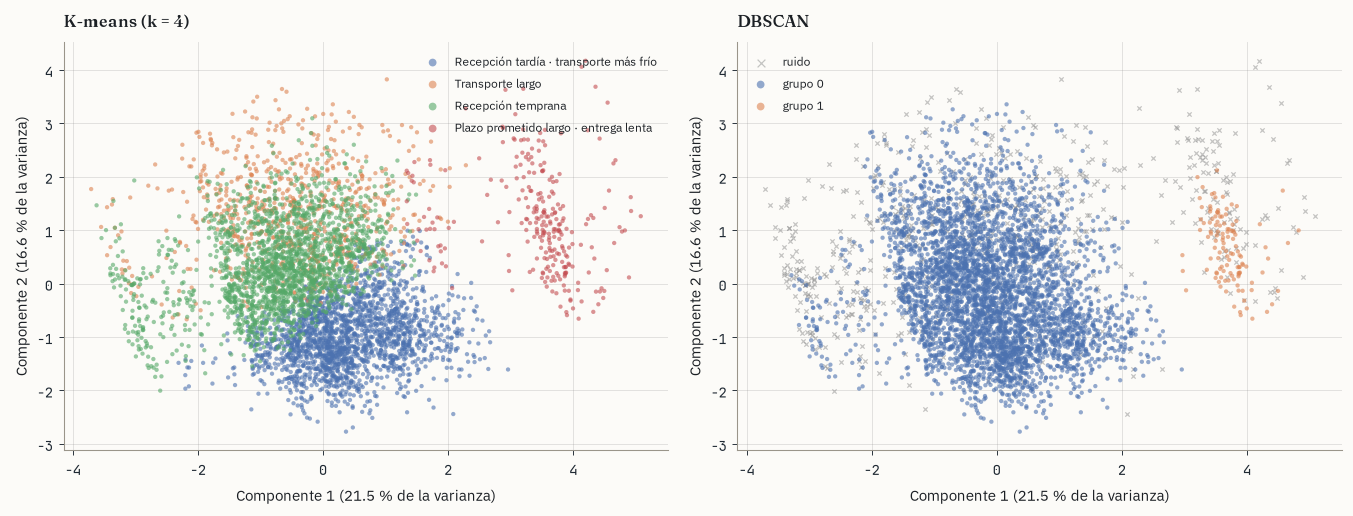

In [6]:
agrupamiento.comparar_particiones(c, "seleccionado").mostrar()

### 2.5 Perfiles: de grupos numerados a perfiles con nombre

El perfil se calcula sobre las variables originales, y cada media se expresa en desviaciones
estándar respecto a la general, lo que permite nombrar el grupo por las variables en que más se
aparta. Los nombres salen del código, no de una lectura a ojo.

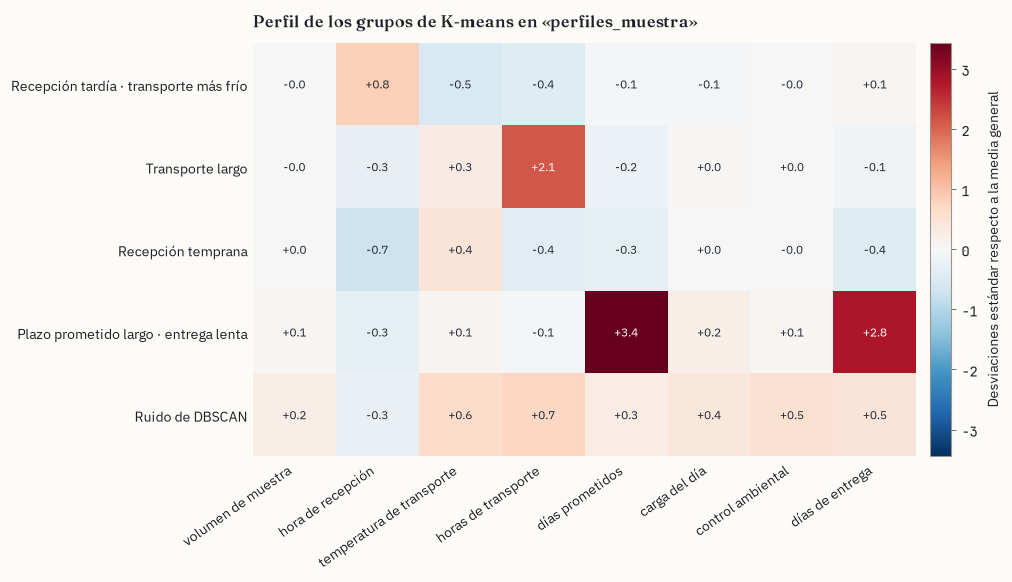

Grupo,n,Proporción,Variables que lo distinguen,Matriz más frecuente,Ensayo más frecuente,Sector más frecuente
Recepción tardía · transporte más frío,2026,0.405,hora de recepción +0.8 DE; temperatura de transporte -0.5 DE,superficie,mesófilos aerobios,cosmético
Transporte largo,753,0.151,horas de transporte +2.1 DE,producto terminado,mesófilos aerobios,cosmético
Recepción temprana,1953,0.391,hora de recepción -0.7 DE,producto terminado,mesófilos aerobios,cosmético
Plazo prometido largo · entrega lenta,268,0.054,días prometidos +3.4 DE; días de entrega +2.8 DE,producto terminado,esterilidad,central de mezclas


Variable,Recepción tardía · transporte más frío,Transporte largo,Recepción temprana,Plazo prometido largo · entrega lenta
volumen de muestra,140.02,140.03,144.21,147.28
hora de recepción,14.11,11.52,10.52,11.47
temperatura de transporte,6.29,11.15,11.99,9.94
horas de transporte,3.98,29.17,4.58,7.67
días prometidos,8.85,8.45,8.17,18.70
carga del día,45.28,46.75,46.31,49.78
control ambiental,1.88,1.88,1.86,2.01
días de entrega,7.31,6.67,5.57,17.40


In [7]:
agrupamiento.perfiles(c, "seleccionado").mostrar()

## 3. Análisis complementario: segmentos de clientes

No ganó la regla de cribado, pero responde la pregunta de negocio más cercana a una decisión
comercial (qué tipos de cliente atiende el laboratorio). Se siguen exactamente las mismas reglas.
Con pocas filas y muchas variables la densidad se diluye, y es esperable que DBSCAN no logre separar
grupos que K-means sí reparte.

In [8]:
agrupamiento.preparacion(c, "complementario").mostrar()

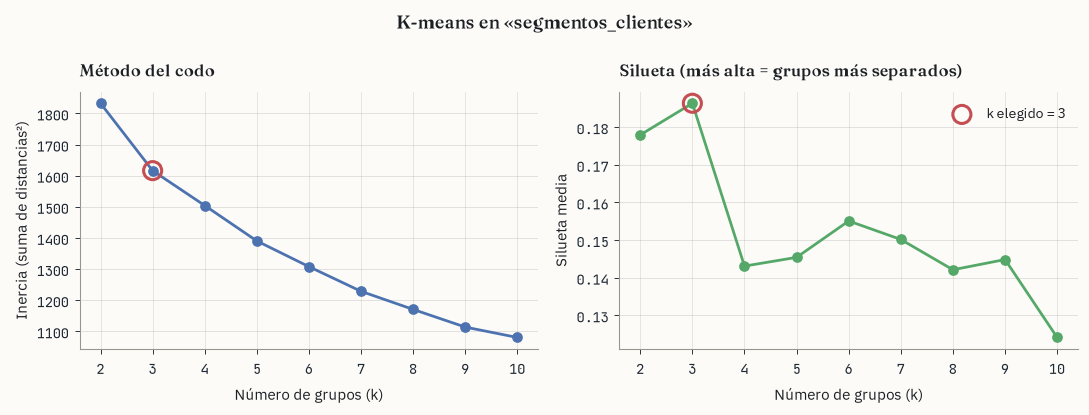

In [9]:
agrupamiento.kmeans(c, "complementario").mostrar()

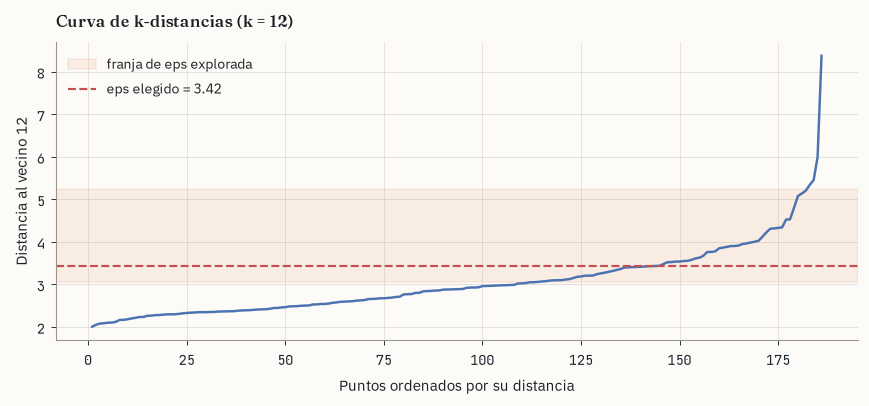

eps,min_samples,Grupos,Ruido,Silueta (sin ruido)
3.04,12,1,0.145,—
3.12,12,1,0.134,—
3.29,12,1,0.108,—
3.42,12,1,0.075,—
3.55,12,1,0.059,—
3.88,12,1,0.027,—
4.24,12,1,0.011,—
5.24,12,1,0.005,—
3.40,24,1,0.102,—
3.49,24,1,0.086,—


id_cliente,muestras,volumen mensual,tamaño de lote,variedad de productos,variedad de ensayos,urgencias,muestreo en planta,no conformidad,entregas tardías,temperatura de llegada,irregularidad de envíos,estacionalidad,antigüedad,Variable más apartada
C026,24.00,1.33,2.40,7.00,5.00,0.00,0.29,0.04,0.25,11.16,0.56,0.92,34.00,estacionalidad (+8.2 DE)
C025,26.00,1.34,3.25,7.00,5.00,0.31,0.00,0.19,0.27,6.85,0.55,0.61,38.00,estacionalidad (+4.8 DE)
C198,54.00,0.83,9.00,4.00,5.00,0.15,0.00,0.00,0.08,15.64,0.72,0.31,243.00,tamaño de lote (+4.5 DE)
C143,121.00,0.53,1.83,7.00,2.00,0.25,0.00,0.13,0.17,16.21,1.54,0.15,1499.00,variedad de ensayos (-4.4 DE)
C194,40.00,0.08,5.00,5.00,2.00,0.00,0.00,0.05,0.11,19.12,0.69,0.18,1089.00,variedad de ensayos (-4.4 DE)
C213,25.00,0.83,5.00,3.00,2.00,0.20,0.00,0.08,0.20,10.37,0.61,0.32,115.00,variedad de ensayos (-4.4 DE)
C182,16.00,0.63,2.29,7.00,5.00,0.06,0.00,0.31,0.44,5.88,0.55,0.38,165.00,entregas tardías (+4.3 DE)
C131,41.00,1.34,6.83,3.00,5.00,0.00,0.63,0.07,0.17,7.54,0.92,0.50,62.00,estacionalidad (+3.7 DE)


In [10]:
agrupamiento.dbscan(c, "complementario").mostrar()

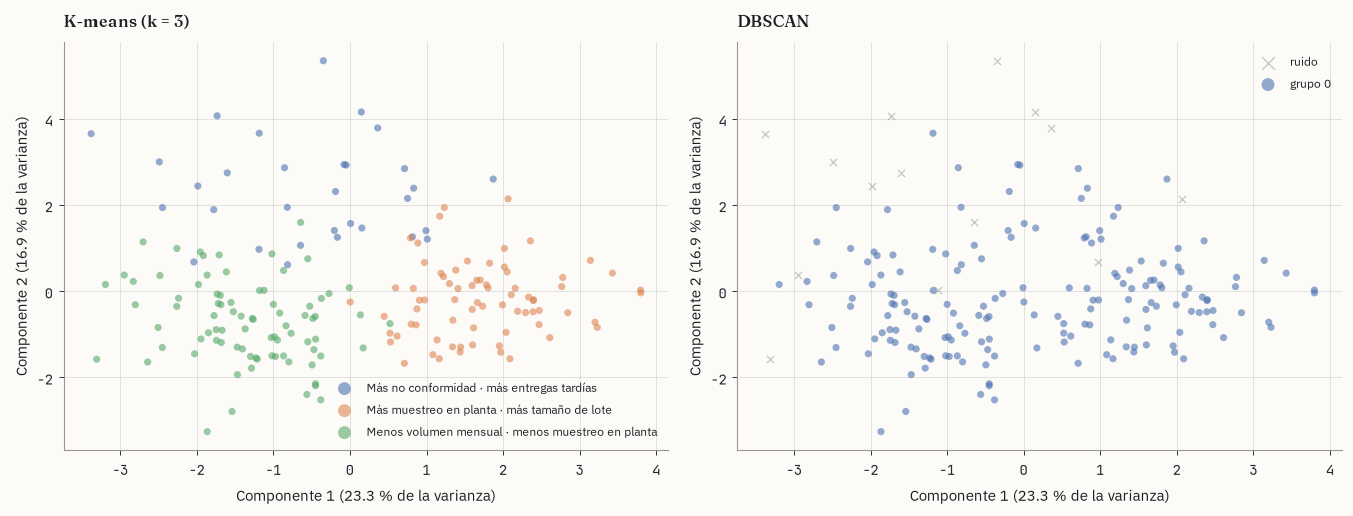

In [11]:
agrupamiento.comparar_particiones(c, "complementario").mostrar()

### Segmentos de clientes y su lectura comercial

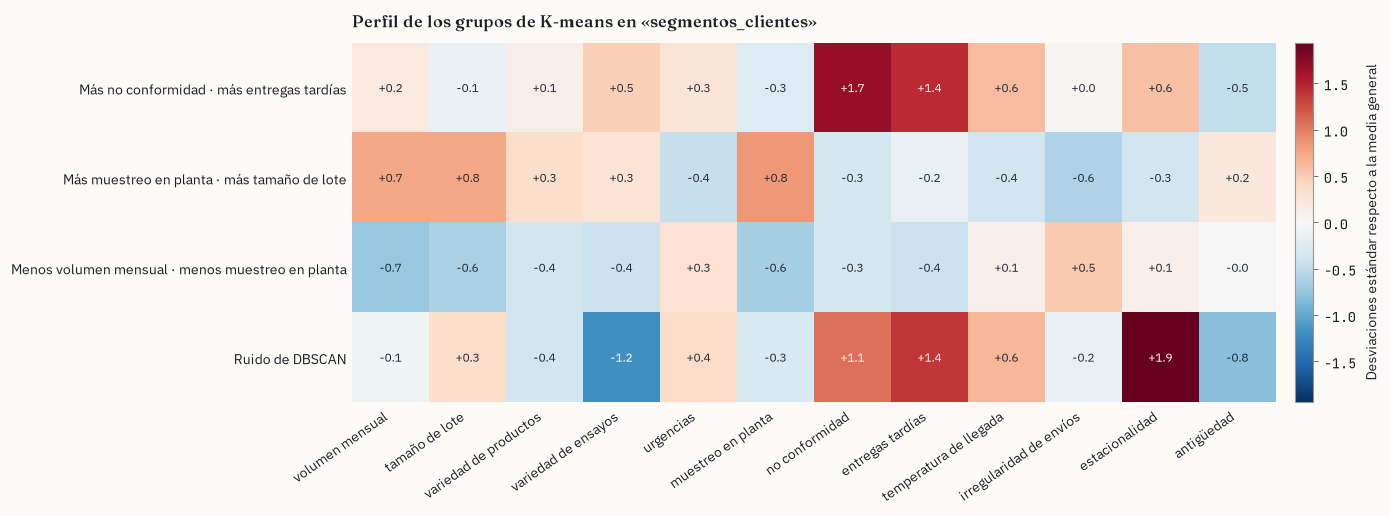

Grupo,n,Proporción,Variables que lo distinguen
Más no conformidad · más entregas tardías,31,0.167,no conformidad +1.7 DE; entregas tardías +1.4 DE; temperatura de llegada +0.6 DE; estacionalidad +0.6 DE
Más muestreo en planta · más tamaño de lote,73,0.392,muestreo en planta +0.8 DE; tamaño de lote +0.8 DE; volumen mensual +0.7 DE; irregularidad de envíos -0.6 DE
Menos volumen mensual · menos muestreo en planta,82,0.441,volumen mensual -0.7 DE; muestreo en planta -0.6 DE; tamaño de lote -0.6 DE; irregularidad de envíos +0.5 DE


Variable,Más no conformidad · más entregas tardías,Más muestreo en planta · más tamaño de lote,Menos volumen mensual · menos muestreo en planta
volumen mensual,0.61,0.87,0.16
tamaño de lote,2.64,3.84,1.95
variedad de productos,6.45,7.18,4.95
variedad de ensayos,5.23,5.10,4.65
urgencias,0.16,0.06,0.17
muestreo en planta,0.11,0.41,0.01
no conformidad,0.22,0.07,0.07
entregas tardías,0.24,0.12,0.11
temperatura de llegada,12.27,8.40,10.27
irregularidad de envíos,0.91,0.74,1.03


Segmento,Clientes,Proporción de clientes,Proporción de muestras,No conformidad,Entregas tardías
Más no conformidad · más entregas tardías,31,0.167,0.114,0.212,0.203
Más muestreo en planta · más tamaño de lote,73,0.392,0.736,0.071,0.119
Menos volumen mensual · menos muestreo en planta,82,0.441,0.150,0.069,0.104


In [12]:
agrupamiento.perfiles(c, "complementario").mostrar()

### Auditoría con la simulación

La simulación asignó a cada cliente un segmento latente que el laboratorio real no conocería; solo
por eso se puede revisar si los grupos encontrados lo recuperan.

In [13]:
agrupamiento.auditoria(c).mostrar()

Segmento latente (simulación),Menos volumen mensual · menos muestreo en planta,Más muestreo en planta · más tamaño de lote,Más no conformidad · más entregas tardías
crítico urgente,18,8,12
estacional,13,14,5
industrial regular,2,39,5
pyme esporádica,49,12,9


## 4. Silueta del cribado frente a la silueta de esta etapa

Las dos cuentas difieren en las filas (el cribado usa solo entrenamiento; aquí, todo el desarrollo)
y en el preprocesamiento (el cribado solo escala; aquí se aplica antes log1p). Para separar los dos
efectos se recalcula la mejor silueta con las filas de esta etapa pero sin log1p.

In [14]:
agrupamiento.silueta_cribado(c).mostrar()

Análisis,Filas (cribado),Filas (etapa 06),k (cribado),Silueta (cribado),"k (filas 06, sin log1p)","Silueta (filas 06, sin log1p)",k (etapa 06),Silueta (etapa 06),Puntaje de la regla (cribado),Puntaje con la silueta de la etapa 06
perfiles_muestra,3834,5000,2,0.433,2,0.434,4,0.148,0.144,0.049
segmentos_clientes,177,186,2,0.182,3,0.183,3,0.186,0.122,0.124


## 5. Síntesis

In [15]:
agrupamiento.sintesis(c).mostrar()

In [16]:
agrupamiento.terminar(c)

← Anterior: [05 · Clasificación y Bayes](05_clasificacion_bayes.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [07 · Evaluación final](07_evaluacion_final.ipynb) →